### Importation des bibliothèques 

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


### Chargement des données 

In [2]:

fichier = r"D:\Projet_stage_data\KuaiRec\KuaiRec 2.0\data\small_matrix.csv"

df = pd.read_csv(fichier, nrows = 100000)

display(df)

,user_id,video_id,play_duration,video_duration,time,date,timestamp,watch_ratio
0,14,148,4381,6067,2020-07-05 05:27:48.378,20200705.0,1.593898e+09,0.722103
1,14,183,11635,6100,2020-07-05 05:28:00.057,20200705.0,1.593898e+09,1.907377
2,14,3649,22422,10867,2020-07-05 05:29:09.479,20200705.0,1.593898e+09,2.063311
3,14,5262,4479,7908,2020-07-05 05:30:43.285,20200705.0,1.593898e+09,0.566388
4,14,8234,4602,11000,2020-07-05 05:35:43.459,20200705.0,1.593899e+09,0.418364
...,...,...,...,...,...,...,...,...
99995,174,7127,4556,9384,2020-07-17 23:21:11.74,20200717.0,1.594999e+09,0.485507
99996,174,2323,6901,12000,2020-07-17 23:22:10.941,20200717.0,1.594999e+09,0.575083
99997,174,9850,5701,4767,2020-07-17 23:23:23.363,20200717.0,1.594999e+09,1.195930
99998,174,2337,3662,4767,2020-07-17 23:27:49.65,20200717.0,1.595000e+09,0.768198


# Explorations des données de la base de données

### Types de données de chaque colonne

In [3]:
print("\nTypes des colonnes :")
display(df.dtypes.to_frame(name="Type"))


Types des colonnes :


,Type
user_id,int64
video_id,int64
play_duration,int64
video_duration,int64
time,str
date,float64
timestamp,float64
watch_ratio,float64


### Nombre de valeurs manquantes par colonne, pourcentage et nombre de lignes dupliquées 

In [4]:
# Nombre de valeurs manquantes par colonne
print("Valeurs manquantes par colonne :")
display(df.isna().sum().to_frame(name="Valeurs manquantes"))

# Pourcentage de valeurs manquantes
print("\nPourcentage de valeurs manquantes :")
display((df.isna().mean() * 100).round(2).to_frame(name="Pourcentage (%)"))

# Nombre de lignes dupliquées dans cet échantillon
print("\nNombre de lignes dupliquées :", df.duplicated().sum())

Valeurs manquantes par colonne :


,Valeurs manquantes
user_id,0
video_id,0
play_duration,0
video_duration,0
time,3787
date,3787
timestamp,3787
watch_ratio,0



Pourcentage de valeurs manquantes :


,Pourcentage (%)
user_id,0.00
video_id,0.00
play_duration,0.00
video_duration,0.00
time,3.79
date,3.79
timestamp,3.79
watch_ratio,0.00



Nombre de lignes dupliquées : 0


### vérification des valeurs aberrantes

In [5]:
display(df.describe())

,user_id,video_id,play_duration,video_duration,date,timestamp,watch_ratio
count,100000.000000,100000.000000,100000.000000,100000.000000,9.621300e+04,9.621300e+04,100000.000000
mean,96.135840,4973.901280,8414.253940,14474.634040,2.020077e+07,1.596226e+09,0.886354
std,52.852581,3065.764898,10487.756471,20430.580326,4.899047e+01,1.261855e+06,1.192066
min,14.000000,103.000000,0.000000,3067.000000,2.020070e+07,1.593878e+09,0.000000
25%,41.000000,2367.000000,5673.000000,7523.000000,2.020072e+07,1.595180e+09,0.465030
50%,102.000000,4698.000000,7506.000000,9600.000000,2.020073e+07,1.596196e+09,0.762503
75%,137.000000,7481.000000,9782.250000,11934.000000,2.020081e+07,1.597131e+09,1.110907
max,174.000000,10595.000000,982111.000000,315072.000000,2.020090e+07,1.599317e+09,111.679668


##### On a le max de watch_ratio superieur a 1 ce qui n'est pas normal dès le premier contact  vu que cette valeur devrait normalement etre inférieure ou égale à 1

In [6]:
ratios = df["watch_ratio"]

print("Ratio supérieur à 1 :", (ratios > 1).sum())
print("Ratio supérieur à 2 :", (ratios > 2).sum())
print("Ratio supérieur à 5 :", (ratios > 5).sum())
print("Ratio supérieur à 10 :", (ratios > 10).sum())

print("\nLes 10 ratios les plus élevés :")
display(
    df.nlargest(10, "watch_ratio")[
        ["user_id", "video_id", "play_duration",
         "video_duration", "watch_ratio"]
    ]
)


Ratio supérieur à 1 : 31682
Ratio supérieur à 2 : 4616
Ratio supérieur à 5 : 377
Ratio supérieur à 10 : 98

Les 10 ratios les plus élevés :


,user_id,video_id,play_duration,video_duration,watch_ratio
99262,172,2344,982111,8794,111.679668
64151,131,2463,751286,7367,101.979910
66048,131,7775,599264,6334,94.610673
30575,55,4012,891965,9900,90.097475
81451,155,9976,823262,10263,80.216506
72603,136,10377,642241,8220,78.131509
64853,131,2765,633238,9400,67.365745
90988,166,7384,409729,6567,62.392112
16480,24,7769,604729,9984,60.569812
21058,37,7113,411695,7500,54.892667


In [7]:
# Nombre d'interactions par utilisateur dans l'échantillon
interactions_user = df.groupby("user_id").size()

print("Nombre d'utilisateurs :", interactions_user.size)
print("\nStatistiques des interactions par utilisateur :")
display(interactions_user.describe().to_frame("Nombre d'interactions"))

print("\nLes 10 utilisateurs ayant le plus d'interactions :")
display(
    interactions_user
    .sort_values(ascending=False)
    .head(10)
    .rename("nombre_interactions")
    .to_frame()
)

Nombre d'utilisateurs : 31

Statistiques des interactions par utilisateur :


,Nombre d'interactions
count,31.000000
mean,3225.806452
std,483.869777
min,619.000000
25%,3307.500000
50%,3313.000000
75%,3318.000000
max,3326.000000



Les 10 utilisateurs ayant le plus d'interactions :


,nombre_interactions
user_id,
137,3326
165,3326
120,3325
41,3324
97,3323
14,3321
51,3319
64,3319
127,3317


In [8]:
# Nombre d'interactions par vidéo dans l'échantillon
interactions_video = df.groupby("video_id").size()

print("Nombre de vidéos distinctes :", interactions_video.size)

print("\nStatistiques des interactions par vidéo :")
display(
    interactions_video.describe()
    .to_frame("Nombre d'interactions")
)

print("\nLes 10 vidéos les plus présentes :")
display(
    interactions_video
    .sort_values(ascending=False)
    .head(10)
    .rename("nombre_interactions")
    .to_frame()
)

Nombre de vidéos distinctes : 3327

Statistiques des interactions par vidéo :


,Nombre d'interactions
count,3327.000000
mean,30.057109
std,0.618698
min,23.000000
25%,30.000000
50%,30.000000
75%,30.000000
max,31.000000



Les 10 vidéos les plus présentes :


,nombre_interactions
video_id,
131,31
133,31
9786,31
139,31
142,31
173,31
171,31
170,31
168,31


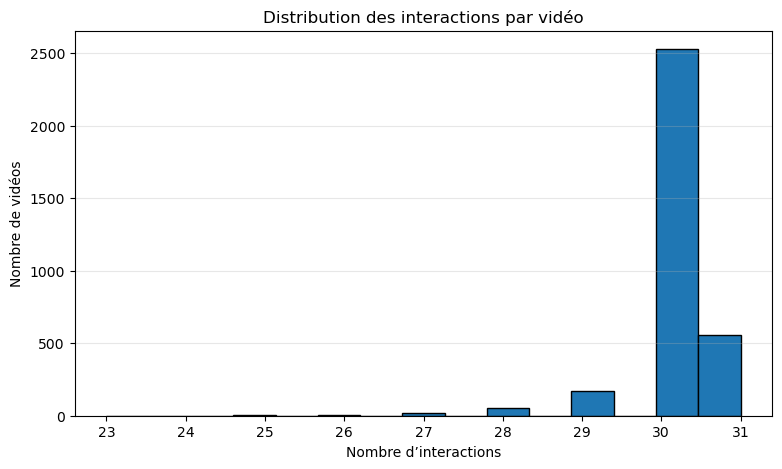

In [9]:
plt.figure(figsize=(9, 5))
plt.hist(interactions_video, bins=15, edgecolor='black')

plt.title('Distribution des interactions par vidéo')
plt.xlabel('Nombre d’interactions')
plt.ylabel('Nombre de vidéos')

plt.grid(axis='y', alpha=0.3)
plt.show()

In [10]:
interactions_video_complet = {}

for bloc in pd.read_csv(fichier, usecols=["video_id"], chunksize=100_000):# chunksize= 100000 : python traite 100000 ligne à la fois
    comptage = bloc["video_id"].value_counts()

    for video_id, nombre in comptage.items():
        if video_id in interactions_video_complet:
            interactions_video_complet[video_id] += nombre
        else:
            interactions_video_complet[video_id] = nombre

print("Nombre total d'interactions :", sum(interactions_video_complet.values()))
print("Nombre de vidéos distinctes :", len(interactions_video_complet))

Nombre total d'interactions : 4676570
Nombre de vidéos distinctes : 3327


In [11]:
interactions_utilisateur = {}

for bloc in pd.read_csv(
    fichier,
    usecols=["user_id"],
    chunksize=100_000
):
    comptage = bloc["user_id"].value_counts()

    for user_id, nombre in comptage.items():
        if user_id in interactions_utilisateur:
            interactions_utilisateur[user_id] += nombre
        else:
            interactions_utilisateur[user_id] = nombre

print("Nombre d'utilisateurs :", len(interactions_utilisateur))
print("Nombre minimal d'interactions :", min(interactions_utilisateur.values()))
print("Nombre maximal d'interactions :", max(interactions_utilisateur.values()))

Nombre d'utilisateurs : 1411
Nombre minimal d'interactions : 3295
Nombre maximal d'interactions : 3327


In [12]:
couples_uniques = set()

for bloc in pd.read_csv(
    fichier,
    usecols=["user_id", "video_id"],
    chunksize=100_000
):
    couples_bloc = bloc.drop_duplicates(
        subset=["user_id", "video_id"]
    )

    couples_uniques.update(
        zip(couples_bloc["user_id"], couples_bloc["video_id"])
    )

print("Nombre de couples utilisateur-vidéo distincts :", len(couples_uniques))
print("Nombre maximal théorique de couples :", 1411 * 3327)

Nombre de couples utilisateur-vidéo distincts : 4676570
Nombre maximal théorique de couples : 4694397


In [13]:
ratios = []

for bloc in pd.read_csv(
    fichier,
    usecols=["watch_ratio"],
    chunksize=100_000
):
    ratios.extend(bloc["watch_ratio"].dropna().tolist())

ratios = pd.Series(ratios)

print(ratios.describe())
print("Ratios supérieurs à 1 :", (ratios > 1).sum())
print("Ratios supérieurs à 2 :", (ratios > 2).sum())

count    4.676570e+06
mean     9.070695e-01
std      1.362324e+00
min      0.000000e+00
25%      4.675769e-01
50%      7.691666e-01
75%      1.120590e+00
max      5.715214e+02
dtype: float64
Ratios supérieurs à 1 : 1514717
Ratios supérieurs à 2 : 217175


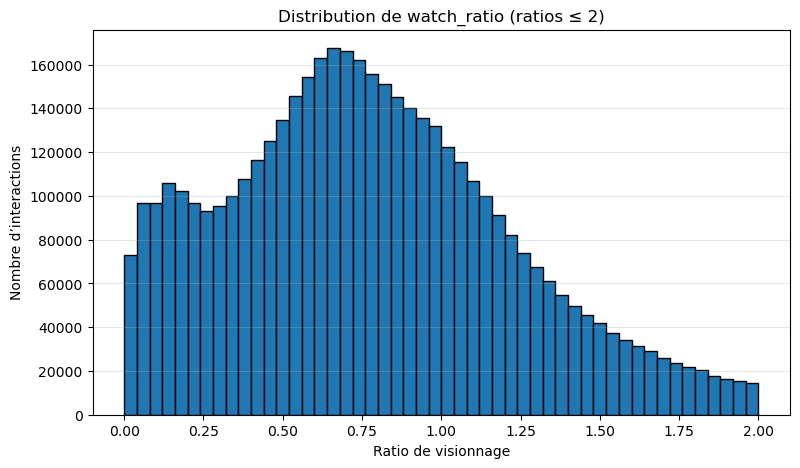

In [14]:
plt.figure(figsize=(9, 5))

plt.hist(ratios[ratios <= 2], bins=50, edgecolor='black')

plt.title('Distribution de watch_ratio (ratios ≤ 2)')
plt.xlabel('Ratio de visionnage')
plt.ylabel('Nombre d’interactions')

plt.grid(axis='y', alpha=0.3)
plt.show()

In [15]:
seuils = [0.5, 0.7, 0.8, 0.9, 1.0]

for seuil in seuils:
    nombre = (ratios >= seuil).sum()
    pourcentage = nombre / len(ratios) * 100

    print(seuil, nombre, round(pourcentage, 2), "%")

print("Nombre de ratios :", len(ratios))

0.5 3401473 72.73 %
0.7 2618784 56.0 %
0.8 2218724 47.44 %
0.9 1851845 39.6 %
1.0 1515050 32.4 %
Nombre de ratios : 4676570


# Début du développemnt du modèle

In [16]:
donnees_recommandation = pd.read_csv(
    fichier,
    usecols=["user_id", "video_id", "watch_ratio"]
)

print("Nombre de lignes :", len(donnees_recommandation))
print("Nombre d'utilisateurs :", donnees_recommandation["user_id"].nunique())
print("Nombre de vidéos :", donnees_recommandation["video_id"].nunique())

Nombre de lignes : 4676570
Nombre d'utilisateurs : 1411
Nombre de vidéos : 3327


In [17]:
print(donnees_recommandation.shape)
print(donnees_recommandation.columns.tolist())

(4676570, 3)
['user_id', 'video_id', 'watch_ratio']


#  modéle

In [18]:
from sklearn.model_selection import train_test_split

entrainement = []
test = []

for utilisateur, groupe in donnees_recommandation.groupby("user_id"):
    train_utilisateur, test_utilisateur = train_test_split(
        groupe,
        test_size=0.2,
        random_state=42
    )

    entrainement.append(train_utilisateur)
    test.append(test_utilisateur)

donnees_entrainement = pd.concat(entrainement)
donnees_test = pd.concat(test)

print("Interactions d'entraînement :", len(donnees_entrainement))
print("Interactions de test :", len(donnees_test))

Interactions d'entraînement : 3740670
Interactions de test : 935900


In [19]:
print("Interactions d'entraînement :", len(donnees_entrainement))
print("Interactions de test :", len(donnees_test))
print("Total :", len(donnees_entrainement) + len(donnees_test))
print("Total initial :", len(donnees_recommandation))

Interactions d'entraînement : 3740670
Interactions de test : 935900
Total : 4676570
Total initial : 4676570


In [20]:
utilisateurs_entrainement = donnees_entrainement["user_id"].nunique()
utilisateurs_test = donnees_test["user_id"].nunique()

print("Utilisateurs dans l'entraînement :", utilisateurs_entrainement)
print("Utilisateurs dans le test :", utilisateurs_test)

Utilisateurs dans l'entraînement : 1411
Utilisateurs dans le test : 1411


In [21]:
utilisateur_test = donnees_test["user_id"].iloc[0]

print("Utilisateur choisi :", utilisateur_test)

Utilisateur choisi : 14


In [22]:
videos_deja_vues = donnees_entrainement[
    donnees_entrainement["user_id"] == utilisateur_test
]["video_id"]

print("Nombre de vidéos déjà vues :", len(videos_deja_vues))

Nombre de vidéos déjà vues : 2656


In [23]:
# Popularité de chaque vidéo, calculée uniquement sur les données d'entraînement
popularite_videos = donnees_entrainement.groupby("video_id").size()

# Vidéos triées de la plus vue à la moins vue
videos_populaires = popularite_videos.sort_values(ascending=False)

display(videos_populaires.head(10))

video_id
8983     1203
1084     1201
5767     1195
2791     1194
4409     1194
2871     1192
1358     1192
4439     1190
825      1189
10396    1189
dtype: int64

In [24]:
videos_deja_vues = set(videos_deja_vues)

recommandations = videos_populaires[
    ~videos_populaires.index.isin(videos_deja_vues)
].head(10)

display(recommandations)

video_id
4409    1194
2871    1192
825     1189
1392    1187
4219    1184
7526    1183
1126    1182
755     1180
6287    1178
7343    1177
dtype: int64

In [25]:
videos_attendues = set(
    donnees_test[
        donnees_test["user_id"] == utilisateur_test
    ]["video_id"]
)

videos_recommandees = set(recommandations.index)

videos_recommandees_pertinentes = (
    videos_recommandees & videos_attendues
)

print(
    "Vidéos recommandées présentes dans le test :",
    len(videos_recommandees_pertinentes)
)

Vidéos recommandées présentes dans le test : 10


In [26]:
precision_10 = (
    len(videos_recommandees_pertinentes)
    / len(videos_recommandees)
)

print("Précision@10 :", precision_10)

Précision@10 : 1.0
